### Importando as bibliotecas que serão utilizadas

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from scipy.spatial import Voronoi, voronoi_plot_2d
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, ConfusionMatrixDisplay
)
from sklearn.decomposition import PCA

RANDOM_STATE = 42
print("Bibliotecas carregadas com sucesso!")

Bibliotecas carregadas com sucesso!


### Lendo o dataset

In [2]:
df = pd.read_csv("../dados/dataset_educacao_desempenho_2000.csv")

df

,idade,horas_estudo_semana,frequencia_percentual,atividades_entregues_percentual,horas_sono,trabalha,deslocamento_minutos,internet_estavel,nota_anterior,participacao_aula,aprovado
0,31,2.0,62.4,49.5,6.3,1,23.9,0,6.1,5.8,0
1,36,16.5,78.9,63.0,6.0,0,37.0,0,7.7,6.9,0
2,43,3.0,88.8,73.8,5.7,0,49.2,1,8.5,5.5,1
3,29,15.7,69.7,71.1,5.0,0,25.9,1,5.0,5.8,0
4,28,17.7,68.1,99.6,5.0,1,10.2,1,7.3,6.8,1
...,...,...,...,...,...,...,...,...,...,...,...
1995,23,11.9,88.2,66.3,6.5,0,143.6,0,6.6,3.9,0
1996,34,10.3,86.7,15.0,5.9,1,69.0,1,6.1,2.7,0
1997,25,1.2,87.4,87.8,7.0,1,25.1,0,6.6,5.0,0
1998,34,14.5,62.2,75.8,8.7,0,7.5,0,3.5,4.1,0


### Informações do dataset

In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 11 columns):
 #   Column                           Non-Null Count  Dtype  
---  ------                           --------------  -----  
 0   idade                            2000 non-null   int64  
 1   horas_estudo_semana              2000 non-null   float64
 2   frequencia_percentual            2000 non-null   float64
 3   atividades_entregues_percentual  2000 non-null   float64
 4   horas_sono                       2000 non-null   float64
 5   trabalha                         2000 non-null   int64  
 6   deslocamento_minutos             2000 non-null   float64
 7   internet_estavel                 2000 non-null   int64  
 8   nota_anterior                    2000 non-null   float64
 9   participacao_aula                2000 non-null   float64
 10  aprovado                         2000 non-null   int64  
dtypes: float64(7), int64(4)
memory usage: 172.0 KB


### Separando X e y

X ficará com as variáveis que usaremos para prever a variável alvo(target) - "aprovado"

In [4]:
X = df.drop(columns=["aprovado"])
y = df["aprovado"]


print("\nDimensão:", df.shape)
print("\nQuantidade por classe:")
print(df["aprovado"].value_counts())
print("\nValores ausentes:", df.isna().sum().sum())


Dimensão: (2000, 11)

Quantidade por classe:
aprovado
0    1338
1     662
Name: count, dtype: int64

Valores ausentes: 0


### Visualização inicial das classes

In [5]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y
)
    
print("Treino:", X_train.shape)
print("Teste :", X_test.shape)
print("\nDistribuição percentual das classes no treino:")
print(y_train.value_counts(normalize=True).sort_index().round(3))
print("\nDistribuição percentual das classes no teste:")
print(y_test.value_counts(normalize=True).sort_index().round(3))

Treino: (1600, 10)
Teste : (400, 10)

Distribuição percentual das classes no treino:
aprovado
0    0.669
1    0.331
Name: proportion, dtype: float64

Distribuição percentual das classes no teste:
aprovado
0    0.67
1    0.33
Name: proportion, dtype: float64


In [6]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [7]:
# Célula — SELECIONE A MEDIDA DE DISTÂNCIA AQUI
METRICA = "euclidean"  # opções: "euclidean", "manhattan", "minkowski", "chebyshev"
P_MINKOWSKI = 3        # usado somente quando METRICA = "minkowski"

K = 3                  # número de vizinhos mais próximos

metricas_validas = ["euclidean", "manhattan", "minkowski", "chebyshev"]
assert METRICA in metricas_validas, f"Escolha uma métrica entre: {metricas_validas}"

parametros_knn = {"n_neighbors": K, "metric": METRICA}
if METRICA == "minkowski":
    parametros_knn["p"] = P_MINKOWSKI

print(f"k selecionado: {K}")
print(f"Métrica selecionada: {METRICA}")
if METRICA == "minkowski":
    print(f"p de Minkowski: {P_MINKOWSKI}")


k selecionado: 3
Métrica selecionada: euclidean


In [8]:
knn = KNeighborsClassifier(**parametros_knn)
knn.fit(X_train_scaled, y_train)
y_pred = knn.predict(X_test_scaled)

print(knn)

KNeighborsClassifier(metric='euclidean', n_neighbors=3)


In [9]:
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred, average="macro", zero_division=0)
recall = recall_score(y_test, y_pred, average="macro", zero_division=0)
f1 = f1_score(y_test, y_pred, average="macro", zero_division=0)

metricas = pd.DataFrame({
    "Métrica": ["Accuracy", "Precision (macro)", "Recall (macro)", "F1-score (macro)"],
    "Valor": [accuracy, precision, recall, f1]
})

display(metricas.style.format({"Valor": "{:.4f}"}))

print("\nRelatório completo por classe:\n")
print(
    classification_report(
        y_test, 
        y_pred, 
        target_names=["Não aprovado", "Aprovado"], 
        zero_division=0)
    )

,Métrica,Valor
0,Accuracy,0.6750
1,Precision (macro),0.6243
2,Recall (macro),0.6133
3,F1-score (macro),0.6167



Relatório completo por classe:

              precision    recall  f1-score   support

Não aprovado       0.74      0.79      0.77       268
    Aprovado       0.51      0.43      0.47       132

    accuracy                           0.68       400
   macro avg       0.62      0.61      0.62       400
weighted avg       0.66      0.68      0.67       400



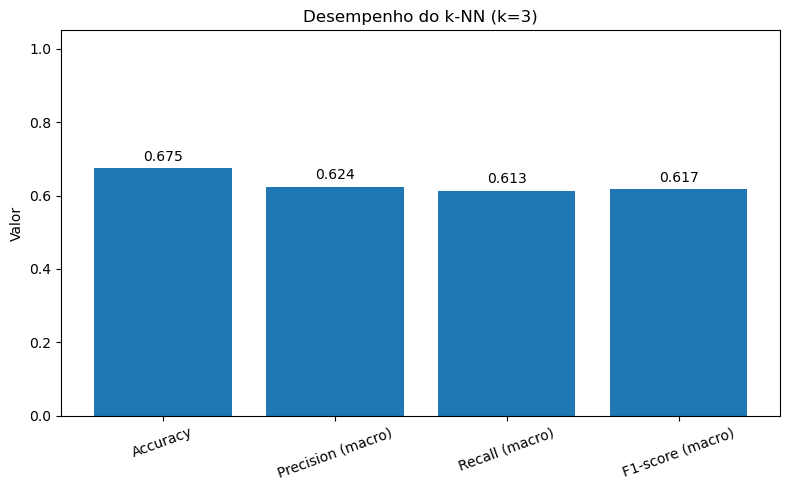

In [10]:
plt.figure(figsize=(8, 5))
plt.bar(metricas["Métrica"], metricas["Valor"])
plt.ylim(0, 1.05)
plt.ylabel("Valor")
plt.title(f"Desempenho do k-NN (k={K})")
plt.xticks(rotation=20)

for i, valor in enumerate(metricas["Valor"]):
    plt.text(i, valor + 0.02, f"{valor:.3f}", ha="center")

plt.tight_layout()
plt.show()

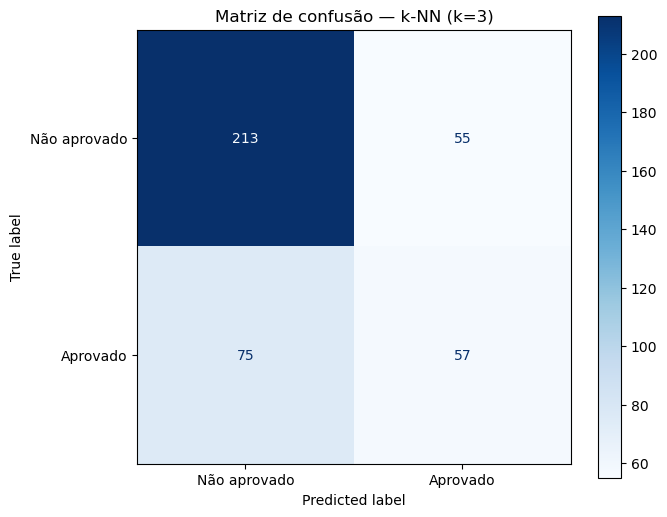

In [11]:
# Célula 10 — Matriz de confusão
fig, ax = plt.subplots(figsize=(7, 6))
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    display_labels=["Não aprovado", "Aprovado"],
    cmap="Blues",
    ax=ax
)
plt.title(f"Matriz de confusão — k-NN (k={K})")
plt.show()

#### Recall da classe “Não aprovado”
Mede quantos alunos que realmente não foram aprovados o modelo conseguiu identificar.
Por exemplo: de 100 alunos que não foram aprovados, se o modelo identificar 80, o recall será de 80%.
É importante quando queremos evitar que alunos com dificuldades passem despercebidos.

In [18]:
resultados_k = []

for k in [1, 3, 5, 7, 11, 15, 25, 51]:
    modelo = KNeighborsClassifier(n_neighbors=k)
    modelo.fit(X_train_scaled, y_train)
    pred = modelo.predict(X_test_scaled)
    resultados_k.append({
        "k": k,
        "Accuracy": accuracy_score(y_test, pred),
        "F1_macro": f1_score(y_test, pred, average="macro", zero_division=0),
        "precision_macro": precision_score(y_test, pred, average="macro", zero_division=0),
        "recall_macro": recall_score(y_test, pred, average="macro", zero_division=0)
    })

resultados_k = pd.DataFrame(resultados_k)
display(resultados_k)

melhor_linha_Accuracy = resultados_k.loc[resultados_k["Accuracy"].idxmax()]
melhor_linha_recall = resultados_k.loc[resultados_k["recall_macro"].idxmax()]
print(f"Maior recall observado: {melhor_linha_recall['recall_macro']:.4f}, com k={int(melhor_linha_recall['k'])}")
print(f"Maior acuracia observada: {melhor_linha_Accuracy['Accuracy']:.4f}, com k={int(melhor_linha_Accuracy['k'])}")

,k,Accuracy,F1_macro,precision_macro,recall_macro
0,1,0.6175,0.566667,0.566801,0.566542
1,3,0.6750,0.616700,0.624256,0.613297
2,5,0.6725,0.603364,0.617024,0.599898
3,7,0.6625,0.575602,0.597609,0.575136
4,11,0.6800,0.598746,0.623543,0.595884
5,15,0.6800,0.576145,0.620346,0.578584
6,25,0.6750,0.566667,0.611269,0.571009
7,51,0.6925,0.570797,0.645982,0.578302


Maior recall observado: 0.6133, com k=3
Maior acuracia observada: 0.6925, com k=51




| **Situação** | **Métrica prioritária** |
|:---|:---:|
| Não deixar passar alunos com risco de reprovação | **Recall** |
| Evitar alertas incorretos sobre alunos que serão aprovados | **Precision** |
| Equilibrar identificação e confiabilidade dos alertas | **F1-score** |
| Medir o acerto geral do modelo | **Accuracy** |

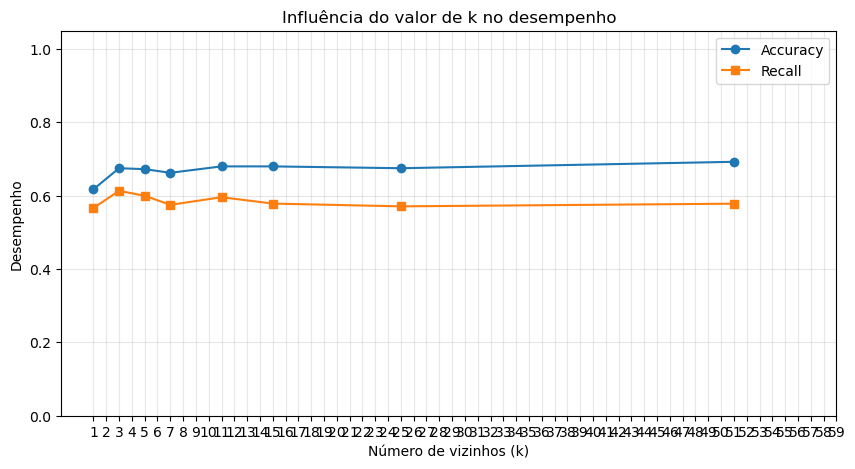

In [27]:
#Gráfico k × desempenho
plt.figure(figsize=(10, 5))
plt.plot(resultados_k["k"], resultados_k["Accuracy"], marker="o", label="Accuracy")
plt.plot(resultados_k["k"], resultados_k["recall_macro"], marker="s", label="Recall")
plt.xlabel("Número de vizinhos (k)")
plt.ylabel("Desempenho")
plt.title("Influência do valor de k no desempenho")
plt.xticks(range(1, 60))
plt.ylim(0, 1.05)
plt.grid(alpha=0.3)
plt.legend()
plt.show()

### Testando com e sem padronização

Como o k-NN depende de distância, a escala dos atributos pode modificar quem é considerado um "vizinho". Vamos comparar o mesmo `k=3`(considerando o k que teve melhor recall) com e sem `StandardScaler`.

In [28]:
knn_sem = KNeighborsClassifier(n_neighbors=3)
knn_sem.fit(X_train, y_train)
pred_sem = knn_sem.predict(X_test)

knn_com = KNeighborsClassifier(n_neighbors=3)
knn_com.fit(X_train_scaled, y_train)
pred_com = knn_com.predict(X_test_scaled)

comparacao = pd.DataFrame({
    "Preparação": ["Sem padronização", "Com StandardScaler"],
    "Accuracy": [
        accuracy_score(y_test, pred_sem),
        accuracy_score(y_test, pred_com)
    ],
    "Precision_macro": [
        precision_score(y_test, pred_sem, average="macro", zero_division=0),
        precision_score(y_test, pred_com, average="macro", zero_division=0)
    ],
    "Recall_macro": [
        recall_score(y_test, pred_sem, average="macro", zero_division=0),
        recall_score(y_test, pred_com, average="macro", zero_division=0)
    ],
    "F1_macro": [
        f1_score(y_test, pred_sem, average="macro", zero_division=0),
        f1_score(y_test, pred_com, average="macro", zero_division=0)
    ]
})

display(comparacao.style.format({
    "Accuracy": "{:.4f}",
    "Precision_macro": "{:.4f}",
    "Recall_macro": "{:.4f}",
    "F1_macro": "{:.4f}"
}))

,Preparação,Accuracy,Precision_macro,Recall_macro,F1_macro
0,Sem padronização,0.6500,0.5844,0.5697,0.5706
1,Com StandardScaler,0.6750,0.6243,0.6133,0.6167


,Accuracy,Precision_macro,Recall_macro,F1_macro
Distância,,,,
Euclidiana,0.6750,0.6243,0.6133,0.6167
Manhattan,0.6550,0.6005,0.5926,0.5950
Minkowski (p=3),0.6700,0.6181,0.6076,0.6108
Chebyshev,0.6500,0.5933,0.5850,0.5872


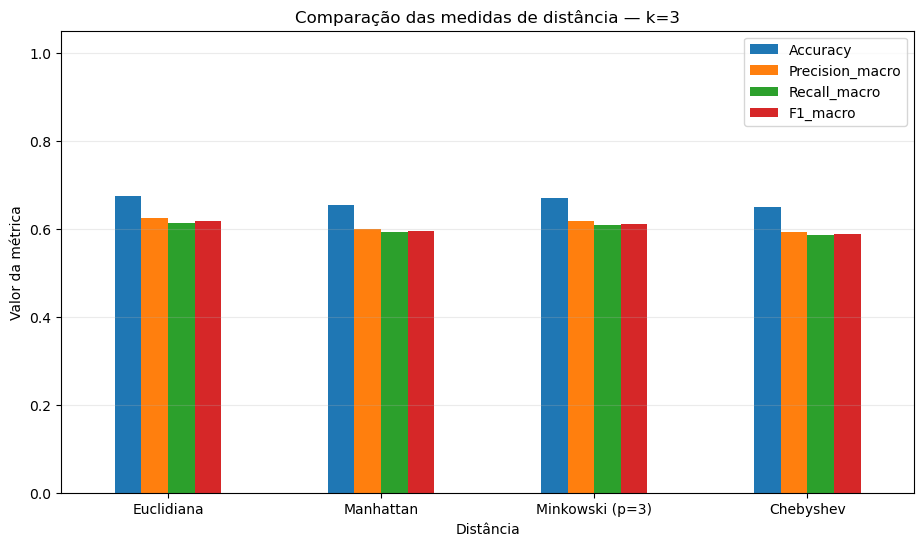

In [29]:
# Comparação automática das medidas de distância
config_metricas = {
    "Euclidiana": {"metric": "euclidean"},
    "Manhattan": {"metric": "manhattan"},
    "Minkowski (p=3)": {"metric": "minkowski", "p": 3},
    "Chebyshev": {"metric": "chebyshev"}
}

resultados_distancias = []
for nome, cfg in config_metricas.items():
    modelo = KNeighborsClassifier(n_neighbors=3, **cfg)
    modelo.fit(X_train_scaled, y_train)
    pred = modelo.predict(X_test_scaled)
    resultados_distancias.append({
        "Distância": nome,
        "Accuracy": accuracy_score(y_test, pred),
        "Precision_macro": precision_score(y_test, pred, average="macro", zero_division=0),
        "Recall_macro": recall_score(y_test, pred, average="macro", zero_division=0),
        "F1_macro": f1_score(y_test, pred, average="macro", zero_division=0)
    })

df_distancias = pd.DataFrame(resultados_distancias).set_index("Distância")
display(df_distancias.style.format("{:.4f}"))

ax = df_distancias.plot(kind="bar", figsize=(11, 6))
ax.set_ylim(0, 1.05)
ax.set_ylabel("Valor da métrica")
ax.set_title(f"Comparação das medidas de distância — k={3}")
ax.grid(axis="y", alpha=0.25)
plt.xticks(rotation=0)
plt.show()


In [30]:
# PCA: preservar 80% da variância
pca = PCA(n_components=0.80)

X_train_pca = pca.fit_transform(X_train_scaled)
X_test_pca = pca.transform(X_test_scaled)

print("Componentes mantidas:", pca.n_components_)
print(
    "Variância explicada:",
    f"{pca.explained_variance_ratio_.sum():.2%}"
)

# KNN com PCA
knn_pca = KNeighborsClassifier(n_neighbors=3)
knn_pca.fit(X_train_pca, y_train)

pred_pca = knn_pca.predict(X_test_pca)

# Comparação com o KNN sem PCA, também com k=3
knn_original = KNeighborsClassifier(n_neighbors=3)
knn_original.fit(X_train_scaled, y_train)

pred_original = knn_original.predict(X_test_scaled)

comparacao_pca = pd.DataFrame({
    "Métrica": [
        "Accuracy",
        "Precision macro",
        "Recall macro",
        "F1 macro"
    ],
    "Sem PCA": [
        accuracy_score(y_test, pred_original),
        precision_score(
            y_test, pred_original,
            average="macro", zero_division=0
        ),
        recall_score(
            y_test, pred_original,
            average="macro", zero_division=0
        ),
        f1_score(
            y_test, pred_original,
            average="macro", zero_division=0
        )
    ],
    "Com PCA": [
        accuracy_score(y_test, pred_pca),
        precision_score(
            y_test, pred_pca,
            average="macro", zero_division=0
        ),
        recall_score(
            y_test, pred_pca,
            average="macro", zero_division=0
        ),
        f1_score(
            y_test, pred_pca,
            average="macro", zero_division=0
        )
    ]
})

display(comparacao_pca.round(4))

Componentes mantidas: 8
Variância explicada: 82.17%


,Métrica,Sem PCA,Com PCA
0,Accuracy,0.6750,0.6425
1,Precision macro,0.6243,0.5810
2,Recall macro,0.6133,0.5717
3,F1 macro,0.6167,0.5734


### 📊 Conclusão do experimento com PCA

Ao comparar os resultados do KNN com e sem a aplicação do PCA, observamos que a redução da dimensionalidade provocou uma diminuição no desempenho do modelo em todas as métricas avaliadas.

- **Accuracy:** diminuiu de 67,50% para 64,25%.
- **Precision macro:** diminuiu de 62,43% para 58,10%.
- **Recall macro:** diminuiu de 61,33% para 57,17%.
- **F1-score macro:** diminuiu de 61,67% para 57,34%.

Esses resultados indicam que, neste experimento, a utilização do PCA não trouxe benefícios para a classificação dos alunos. A transformação das variáveis originais em componentes principais pode ter descartado ou dificultado o aproveitamento de informações relevantes para a tarefa de previsão.

## Conclusão — Modelo KNN

Durante os experimentos, observamos que a escolha do valor de \(k\) influencia o comportamento do modelo, especialmente na identificação de cada classe. Embora alguns valores tenham apresentado acurácia semelhante, as métricas de recall e F1-score permitiram observar diferenças importantes no desempenho da classificação.

Entre os valores testados, selecionamos **\(k=3\) como o melhor candidato para o KNN**, pois apresentou acurácia de aproximadamente 68% e recall macro de aproximadamente 0,61. Além disso, o recall foi de aproximadamente 0,79 para a classe “Não aprovado” e 0,43 para a classe “Aprovado”. Esses resultados indicam um desempenho mais equilibrado entre as classes do que o observado com \(k=6\), cujo recall para a classe “Aprovado” foi de apenas 0,25.

Apesar disso, o modelo ainda apresenta dificuldade para identificar os alunos aprovados, mostrando que existe espaço para melhorias. O balanceamento de classes seria um caminho, mas seguindo a ordem do que foi pedidio no trabalho, vamos avaliar o segundo algoritmo proposto para o projeto, o Support Vector Machine (SVM). 